# Previsão mensal de internações por estado (SIH/DATASUS)

**Contexto.** Superlotação e demanda imprevisível pressionam o SUS. Gestores precisam saber *com antecedência* quanto de demanda cada estado deve receber para remanejar equipes e leitos. Esse notebook é a parte de Machine Learning da proposta CitizenTech (painel de gestão com previsão de picos).

**Pergunta.** Dado o histórico de internações de uma UF, quantas internações ela terá no mês seguinte?

**Dados.** `data/processed/internacoes_tratado.csv`, gerado a partir do SIH/DATASUS: internações mensais das 27 UFs, de jan/2008 a ago/2026.

> As internações hospitalares são uma aproximação da demanda: não incluem atendimentos de UPA/UBS. Quando os dados de clima (INMET) e população (IBGE) entrarem em `data/`, podemos usá-los como preditoras.

**Abordagem.** Regressão com um modelo único para as 27 UFs, split temporal (treino até 2023, holdout a partir de 2024) e validação cruzada temporal só dentro do treino.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

## 1. Dados

- **Alvo:** `valor` (internações no mês).
- **Unidade de análise:** uma UF em um mês.

In [2]:
df = pd.read_csv("../../data/processed/internacoes_tratado.csv", parse_dates=["data"])
print(df.shape)
df.head()

(6048, 4)


,codigo_uf,estado,data,valor
0,11,Rondônia,2008-01-01,4142
1,11,Rondônia,2008-02-01,7301
2,11,Rondônia,2008-03-01,4318
3,11,Rondônia,2008-04-01,4285
4,11,Rondônia,2008-05-01,4511


In [3]:
print(df.dtypes, end="\n\n")
print("Nulos:", df.isna().sum().sum())
print("Período:", df["data"].min().date(), "a", df["data"].max().date())
print("UFs:", df["codigo_uf"].nunique())
df["valor"].describe().round(0)

codigo_uf             int64
estado                  str
data         datetime64[us]
valor                 int64
dtype: object

Nulos: 0
Período: 2008-01-01 a 2026-08-01
UFs: 27


count      6048.0
mean      36732.0
std       41578.0
min           0.0
25%       13065.0
50%       19266.0
75%       46866.0
max      254595.0
Name: valor, dtype: float64

Nenhum nulo, mas há meses com valor 0 em estados que nunca ficam sem internação. Eram células `-` no arquivo original, que o tratamento converteu em 0:

In [4]:
df[df["valor"] == 0]

,codigo_uf,estado,data,valor
244,12,Acre,2009-09-01,0
447,12,Acre,2026-08-01,0
895,14,Roraima,2026-08-01,0


Acre e Roraima em ago/2026 (último mês, ainda não publicado para esses estados) e Acre em set/2009 não são zeros reais, e sim dados ausentes. Aqui eles viram `NaN` para não contaminar o alvo nem as defasagens; as linhas afetadas saem na hora de montar as variáveis.

In [5]:
df["valor"] = df["valor"].replace(0, np.nan)
df["valor"].isna().sum()

np.int64(3)

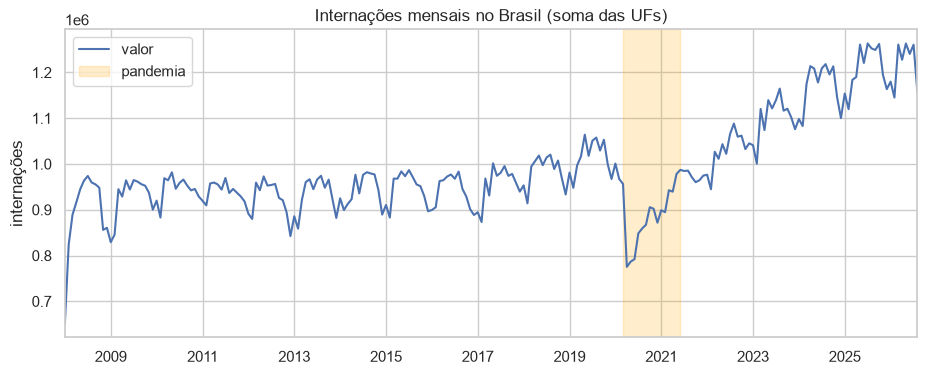

In [6]:
total = df.groupby("data")["valor"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
total.plot(ax=ax)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="orange", alpha=0.2, label="pandemia")
ax.set_title("Internações mensais no Brasil (soma das UFs)")
ax.set_ylabel("internações")
ax.set_xlabel("")
ax.legend()
plt.show()

A série tem sazonalidade anual clara e uma queda forte em 2020 (pandemia). Esse período fica no treino e pode atrapalhar um pouco os modelos; vale lembrar na análise final.

O volume varia muito entre estados, então olhamos a escala por UF:

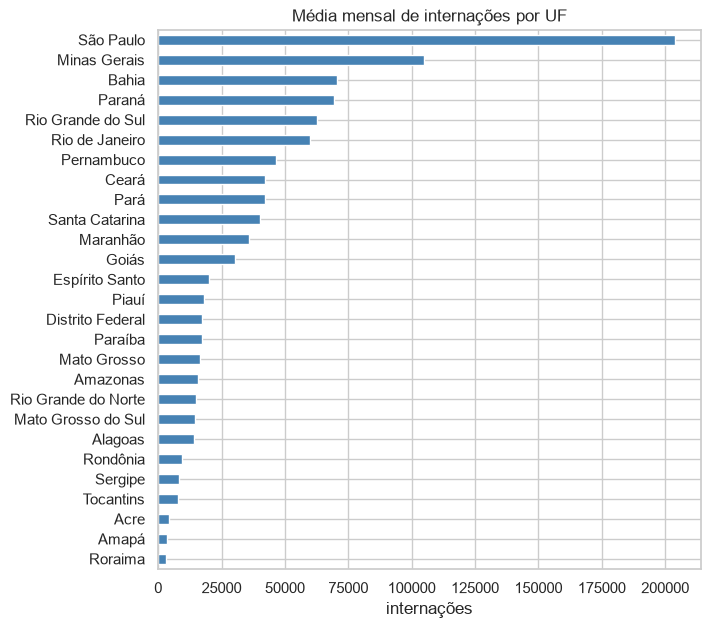

In [7]:
media_uf = df.groupby("estado")["valor"].mean().sort_values()

fig, ax = plt.subplots(figsize=(7, 7))
media_uf.plot.barh(ax=ax, color="steelblue")
ax.set_title("Média mensal de internações por UF")
ax.set_xlabel("internações")
ax.set_ylabel("")
plt.show()

## 2. Variáveis preditoras

Para prever o mês `t` usamos somente informação até `t-1`:

| variável | descrição |
|---|---|
| `lag_1`, `lag_2`, `lag_3` | internações 1, 2 e 3 meses atrás |
| `lag_12` | internações no mesmo mês do ano anterior |
| `media_3m`, `media_12m` | média dos 3 / 12 meses anteriores |
| `mes` | mês do calendário (sazonalidade) |
| `codigo_uf` | estado |

Não usamos o ano como variável: os modelos de árvore não extrapolam, e a tendência já aparece nas defasagens.

In [8]:
def criar_variaveis(base):
    base = base.sort_values(["codigo_uf", "data"]).copy()
    por_uf = base.groupby("codigo_uf")["valor"]

    for meses in (1, 2, 3, 12):
        base[f"lag_{meses}"] = por_uf.shift(meses)

    # o shift(1) garante que a média não inclui o mês que estamos prevendo
    for janela in (3, 12):
        base[f"media_{janela}m"] = por_uf.transform(
            lambda s: s.shift(1).rolling(janela).mean()
        )

    base["mes"] = base["data"].dt.month
    return base.dropna().reset_index(drop=True)


dados = criar_variaveis(df)
print(dados.shape, "- primeiros meses de cada UF descartados por falta de histórico")
dados.head()

(5709, 11) - primeiros meses de cada UF descartados por falta de histórico


,codigo_uf,estado,data,valor,lag_1,lag_2,lag_3,lag_12,media_3m,media_12m,mes
0,11,Rondônia,2009-01-01,6441.0,6609.0,7004.0,7098.0,4142.0,6903.666667,5985.083333,1
1,11,Rondônia,2009-02-01,7501.0,6441.0,6609.0,7004.0,7301.0,6684.666667,6176.666667,2
2,11,Rondônia,2009-03-01,7835.0,7501.0,6441.0,6609.0,4318.0,6850.333333,6193.333333,3
3,11,Rondônia,2009-04-01,7882.0,7835.0,7501.0,6441.0,4285.0,7259.000000,6486.416667,4
4,11,Rondônia,2009-05-01,8462.0,7882.0,7835.0,7501.0,4511.0,7739.333333,6786.166667,5


## 3. Divisão temporal (treino e holdout)

Nada de embaralhar: treino vai até dez/2023 e o holdout começa em jan/2024. O holdout só é usado na avaliação final.

In [9]:
CORTE = pd.Timestamp("2024-01-01")
COL_NUM = ["lag_1", "lag_2", "lag_3", "lag_12", "media_3m", "media_12m"]
COL_CAT = ["codigo_uf", "mes"]

# ordenado por data (e não por UF) para o TimeSeriesSplit respeitar o tempo
treino = dados[dados["data"] < CORTE].sort_values(["data", "codigo_uf"])
teste = dados[dados["data"] >= CORTE].sort_values(["data", "codigo_uf"])

X_treino, y_treino = treino[COL_NUM + COL_CAT], treino["valor"]
X_teste, y_teste = teste[COL_NUM + COL_CAT], teste["valor"]

print(f"treino: {treino['data'].min():%Y-%m} a {treino['data'].max():%Y-%m} ({len(treino)} linhas)")
print(f"teste:  {teste['data'].min():%Y-%m} a {teste['data'].max():%Y-%m} ({len(teste)} linhas)")

treino: 2009-01 a 2023-12 (4847 linhas)
teste:  2024-01 a 2026-08 (862 linhas)


## 4. Métricas e baselines

Antes dos modelos, dois baselines simples que qualquer modelo precisa superar:
- **último mês** (`lag_1`)
- **mesmo mês do ano anterior** (`lag_12`)

Métricas: MAE (erro médio em internações), RMSE (pune erros grandes), R² e MAPE (erro percentual, útil para comparar UFs de tamanhos diferentes). Também medimos quantas vezes o modelo **subestima** a demanda, que é o erro mais caro para quem planeja equipes.

In [10]:
def avaliar(real, previsto):
    return {
        "MAE": mean_absolute_error(real, previsto),
        "RMSE": np.sqrt(mean_squared_error(real, previsto)),
        "R2": r2_score(real, previsto),
        "MAPE (%)": mean_absolute_percentage_error(real, previsto) * 100,
        "subestimou (%)": (previsto < real).mean() * 100,
    }


ARREDONDAR = {"MAE": 0, "RMSE": 0, "R2": 3, "MAPE (%)": 1, "subestimou (%)": 1}


previsoes = {
    "Baseline: último mês": X_teste["lag_1"],
    "Baseline: mesmo mês ano anterior": X_teste["lag_12"],
}
pd.DataFrame({nome: avaliar(y_teste, p) for nome, p in previsoes.items()}).T.round(ARREDONDAR)

,MAE,RMSE,R2,MAPE (%),subestimou (%)
Baseline: último mês,1755.0,3315.0,0.995,5.8,49.4
Baseline: mesmo mês ano anterior,2396.0,4072.0,0.993,7.7,71.7


## 5. Modelos

Três modelos supervisionados, cada um dentro de um `Pipeline` que codifica UF e mês (one-hot) e, no caso da Ridge, padroniza as variáveis numéricas. O pipeline é ajustado apenas com o treino.

Os hiperparâmetros são escolhidos com `TimeSeriesSplit` sobre o treino: cada fold valida em 12 meses (27 UFs × 12) e treina só com o que veio antes.

In [11]:
def montar_pipeline(modelo, escalar=False):
    numericas = StandardScaler() if escalar else "passthrough"
    preparo = ColumnTransformer([
        ("num", numericas, COL_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COL_CAT),
    ])
    return Pipeline([("preparo", preparo), ("modelo", modelo)])


N_UFS = dados["codigo_uf"].nunique()
cv = TimeSeriesSplit(n_splits=5, test_size=N_UFS * 12)

candidatos = {
    "Ridge": (
        montar_pipeline(Ridge(), escalar=True),
        {"modelo__alpha": [1, 10, 100, 1000]},
    ),
    "Random Forest": (
        montar_pipeline(RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)),
        {"modelo__max_depth": [8, 16, None], "modelo__min_samples_leaf": [1, 3, 5]},
    ),
    "Gradient Boosting": (
        montar_pipeline(HistGradientBoostingRegressor(random_state=SEED)),
        {"modelo__learning_rate": [0.05, 0.1],
         "modelo__max_iter": [200, 400],
         "modelo__max_depth": [3, None]},
    ),
}

In [12]:
modelos = {}
resumo_cv = []

for nome, (pipeline, grade) in candidatos.items():
    busca = GridSearchCV(pipeline, grade, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    busca.fit(X_treino, y_treino)
    modelos[nome] = busca.best_estimator_
    resumo_cv.append({"modelo": nome, "MAE (CV)": -busca.best_score_, "melhores parâmetros": busca.best_params_})

resumo_cv = pd.DataFrame(resumo_cv).set_index("modelo")
resumo_cv.round(1)

,MAE (CV),melhores parâmetros
modelo,,
Ridge,1612.4,{'modelo__alpha': 100}
Random Forest,1768.9,"{'modelo__max_depth': 8, 'modelo__min_samples_..."
Gradient Boosting,1660.6,"{'modelo__learning_rate': 0.1, 'modelo__max_de..."


## 6. Avaliação no holdout (2024 em diante)

Agora sim usamos o teste, uma única vez, para comparar tudo.

In [13]:
for nome, modelo in modelos.items():
    previsoes[nome] = pd.Series(modelo.predict(X_teste), index=X_teste.index)

tabela = pd.DataFrame({nome: avaliar(y_teste, p) for nome, p in previsoes.items()}).T
tabela.sort_values("MAE").round(ARREDONDAR)

,MAE,RMSE,R2,MAPE (%),subestimou (%)
Ridge,1500.0,2920.0,0.996,5.6,54.2
Baseline: último mês,1755.0,3315.0,0.995,5.8,49.4
Gradient Boosting,2212.0,5086.0,0.989,5.6,53.4
Random Forest,2385.0,5150.0,0.989,6.0,55.8
Baseline: mesmo mês ano anterior,2396.0,4072.0,0.993,7.7,71.7


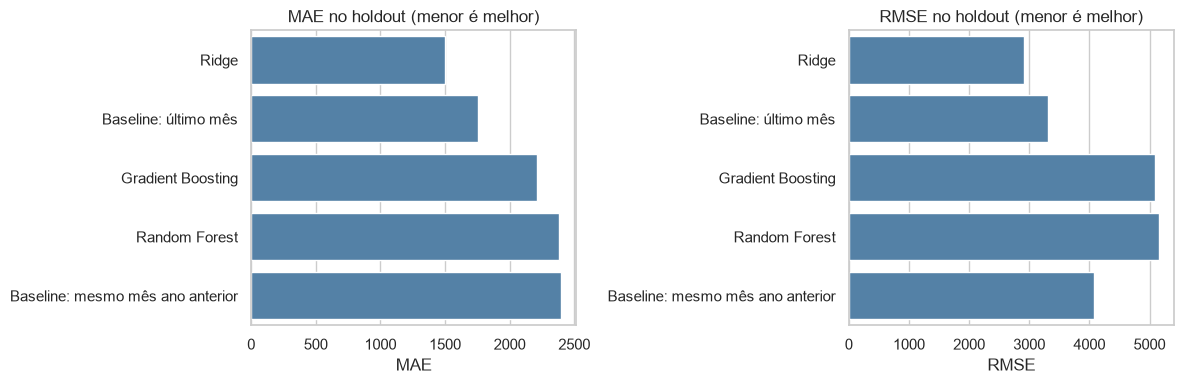

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
ordem = tabela.sort_values("MAE").index

for ax, metrica in zip(eixos, ["MAE", "RMSE"]):
    sns.barplot(x=tabela.loc[ordem, metrica], y=ordem, ax=ax, color="steelblue")
    ax.set_title(f"{metrica} no holdout (menor é melhor)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

O modelo escolhido é o de menor MAE na **validação cruzada** (e não no teste), para o holdout continuar sendo uma avaliação honesta.

In [15]:
escolhido = resumo_cv["MAE (CV)"].idxmin()
modelo_final = modelos[escolhido]
prev_final = previsoes[escolhido]
print("Modelo escolhido pela validação cruzada:", escolhido)

Modelo escolhido pela validação cruzada: Ridge


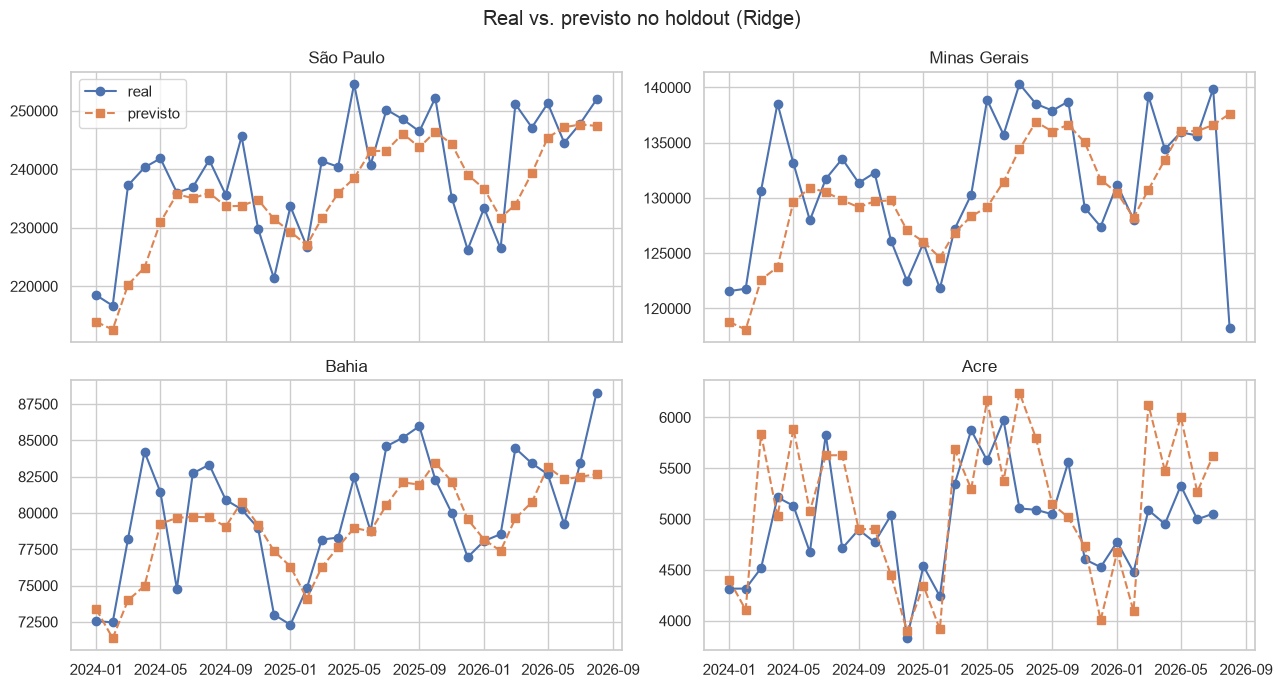

In [16]:
ufs_exemplo = {35: "São Paulo", 31: "Minas Gerais", 29: "Bahia", 12: "Acre"}

fig, eixos = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, (codigo, nome_uf) in zip(eixos.ravel(), ufs_exemplo.items()):
    filtro = teste["codigo_uf"] == codigo
    ax.plot(teste.loc[filtro, "data"], y_teste[filtro], marker="o", label="real")
    ax.plot(teste.loc[filtro, "data"], prev_final[filtro], marker="s", linestyle="--", label="previsto")
    ax.set_title(nome_uf)
axes_leg = eixos[0, 0].legend()
fig.suptitle(f"Real vs. previsto no holdout ({escolhido})")
plt.tight_layout()
plt.show()

### Erro por UF

Como o MAE absoluto é dominado pelos estados grandes, o erro percentual mostra se o modelo funciona também nos estados pequenos.

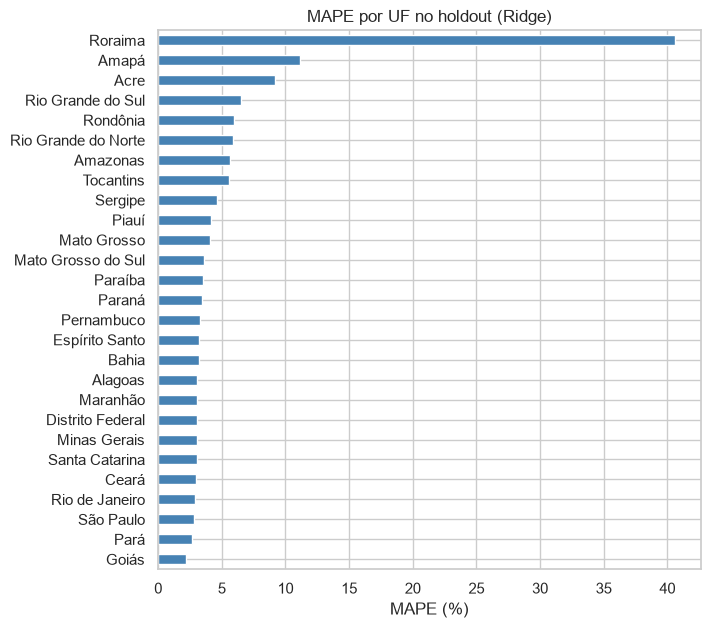

,MAE,MAPE (%)
codigo_uf,,
Rondônia,638.3,6.0
Rio Grande do Sul,3269.0,6.5
Acre,458.4,9.2
Amapá,543.8,11.1
Roraima,711.9,40.6


In [17]:
erros = teste[["codigo_uf", "data"]].assign(real=y_teste, previsto=prev_final)
erros["erro_pct"] = (erros["previsto"] - erros["real"]) / erros["real"] * 100

nomes_uf = df.drop_duplicates("codigo_uf").set_index("codigo_uf")["estado"]
por_uf = erros.groupby("codigo_uf").apply(
    lambda g: pd.Series({
        "MAE": mean_absolute_error(g["real"], g["previsto"]),
        "MAPE (%)": mean_absolute_percentage_error(g["real"], g["previsto"]) * 100,
    })
)
por_uf.index = por_uf.index.map(nomes_uf)
por_uf = por_uf.sort_values("MAPE (%)")

fig, ax = plt.subplots(figsize=(7, 7))
por_uf["MAPE (%)"].plot.barh(ax=ax, color="steelblue")
ax.set_title(f"MAPE por UF no holdout ({escolhido})")
ax.set_xlabel("MAPE (%)")
ax.set_ylabel("")
plt.show()

por_uf.round(1).tail(5)

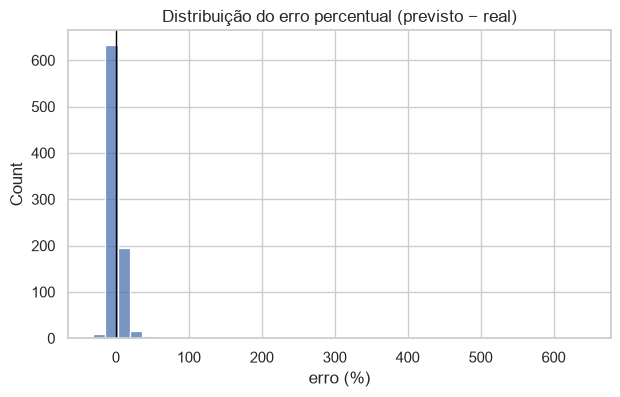

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(erros["erro_pct"], bins=40, ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Distribuição do erro percentual (previsto − real)")
ax.set_xlabel("erro (%)")
plt.show()

## 7. Importância das variáveis

Importância por permutação no holdout: embaralhamos uma variável por vez e vemos quanto o MAE piora. Quanto maior a piora, mais o modelo depende dela.

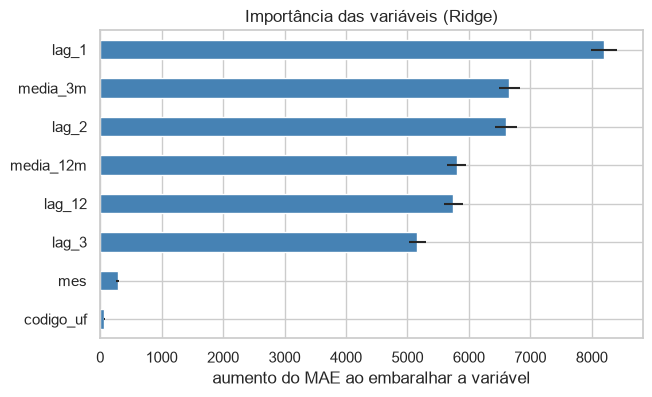

lag_1        8197.2
media_3m     6657.3
lag_2        6603.6
media_12m    5801.9
lag_12       5748.8
lag_3        5163.1
mes           281.8
codigo_uf      69.0
dtype: float64

In [19]:
importancia = permutation_importance(
    modelo_final, X_teste, y_teste,
    scoring="neg_mean_absolute_error", n_repeats=20, random_state=SEED, n_jobs=-1,
)
ranking = pd.Series(importancia.importances_mean, index=X_teste.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ranking.plot.barh(ax=ax, xerr=importancia.importances_std[ranking.index.map(X_teste.columns.get_loc)], color="steelblue")
ax.set_title(f"Importância das variáveis ({escolhido})")
ax.set_xlabel("aumento do MAE ao embaralhar a variável")
plt.show()

ranking.sort_values(ascending=False).round(1)

## 8. Conclusão

| modelo | MAE (CV) | MAE (holdout) | RMSE (holdout) | MAPE (holdout) |
|---|---|---|---|---|
| **Ridge** | 1.612 | **1.500** | **2.920** | 5,6% |
| Gradient Boosting | 1.661 | 2.212 | 5.086 | 5,6% |
| Random Forest | 1.769 | 2.385 | 5.150 | 6,0% |
| Baseline: último mês | - | 1.755 | 3.315 | 5,8% |
| Baseline: mesmo mês do ano anterior | - | 2.396 | 4.072 | 7,7% |

**Modelo escolhido: Ridge.** Foi o melhor na validação cruzada temporal e se manteve o melhor no holdout, com MAE de cerca de 1.500 internações por UF/mês (erro percentual médio de 5,6%). É o único dos três que supera o baseline "último mês" em MAE e RMSE. Os modelos de árvore ficaram abaixo do baseline simples no MAE.

Por que a Ridge ganhou: a série é muito regular e depende quase só dos últimos meses (as variáveis mais importantes são `lag_1`, `media_3m` e `lag_2`). Árvores não extrapolam valores fora do que viram no treino, e a demanda de 2024 em diante ficou em patamares que o modelo linear acompanha melhor.

O erro de subestimar demanda é mais caro que o de superestimar, pois deixa equipes e leitos abaixo do necessário. A Ridge subestimou em 54% dos meses, um pouco acima do baseline "último mês" (49%). Na prática, vale somar uma margem de segurança à previsão antes de planejar escalas.

## 9. Análise

**Escolhas.** O modelo é único para as 27 UFs, o que dá mais dados ao ajuste e permite prever estados com séries curtas ou ruidosas. A divisão foi cronológica (treino até 2023, teste de 2024 a ago/2026), a validação cruzada usou `TimeSeriesSplit` apenas no treino, e todo o pré-processamento ficou dentro do `Pipeline`. O holdout foi usado uma vez, só para a comparação final. O modelo foi escolhido pela validação cruzada, e não pelo resultado do teste.

**Limitações.**
- **Previsão de um passo.** No teste, cada previsão usa as internações reais dos meses anteriores. Para prever vários meses à frente, o erro tende a crescer, porque as defasagens teriam de vir de previsões.
- **Pandemia.** A queda de 2020 está no treino e distorce as médias de 12 meses de quem a viu.
- **Dados recentes incompletos.** Há meses finais ainda não consolidados: Acre e Roraima em ago/2026 vieram vazios (tratados como ausentes aqui), e Roraima em jul/2026 tem 515 internações contra cerca de 3.000 nos meses vizinhos. Isso explica parte do MAPE de 40,6% de Roraima e prejudica a avaliação dos estados pequenos. O ideal é baixar o dado de novo quando o DATASUS fechar esses meses.
- **Estados pequenos.** Os erros absolutos são dominados pelos estados grandes. Em percentual, Amapá (11,1%), Acre (9,2%) e Roraima (40,6%) são os mais difíceis de prever.
- **Internações não são atendimentos de UPA/UBS.** O SIH registra apenas internações hospitalares. Servem como aproximação da pressão sobre o sistema, mas não medem fila nem lotação de pronto atendimento.
- **Sem variáveis externas.** O modelo só enxerga o histórico. Clima (INMET), população e faixa etária (IBGE) podem ajudar a antecipar picos, e entram assim que os dados chegarem a `data/`.

**Vieses.** Estados com menos estrutura de saúde ou com subnotificação tendem a ter séries menores e mais ruidosas, e o modelo erra mais neles em termos percentuais. Se a previsão fosse usada para distribuir recursos, esses estados poderiam receber menos que o necessário. Por isso o erro deve ser monitorado por UF, e não só no total, e as previsões devem ser cruzadas com densidade populacional.

**Contribuição para a decisão.** A previsão de internações do mês seguinte por UF, com erro médio em torno de 5% (nos estados com dados completos), dá ao gestor uma referência para antecipar escalas, leitos e estoques, que é o objetivo do painel de gestão da proposta. O uso mais seguro é como apoio à decisão, com margem para subestimativa e acompanhamento do erro por estado.
